# Week 4 Lab: A* Search for the 8-Puzzle

Implement A* and compare two heuristics, **Misplaced Tiles** and **Manhattan Distance**, by the number of nodes each makes A* expand.

## 1. Problem Representation
State: tuple of 9 ints, 0 = blank, read left-to-right top-to-bottom.

Goal state: `(1, 2, 3, 4, 5, 6, 7, 8, 0)`

Actions are the direction the **blank** moves; every move costs 1.

In [1]:
import heapq
import itertools
import random

GOAL_STATE = (1, 2, 3, 4, 5, 6, 7, 8, 0)

In [2]:
def get_blank_position(state):
    """Return the index (0-8) of the blank tile (0) in the state tuple."""
    return state.index(0)

def get_neighbors(state):
    """Return a list of (new_state, action) pairs reachable by sliding one tile into the blank."""
    neighbors = []
    blank = get_blank_position(state)
    row, col = divmod(blank, 3)

    moves = {
        "Up":    (row - 1, col),
        "Down":  (row + 1, col),
        "Left":  (row, col - 1),
        "Right": (row, col + 1),
    }

    for action, (new_row, new_col) in moves.items():
        if 0 <= new_row < 3 and 0 <= new_col < 3:
            new_blank = new_row * 3 + new_col
            new_state = list(state)
            new_state[blank], new_state[new_blank] = new_state[new_blank], new_state[blank]
            neighbors.append((tuple(new_state), action))

    return neighbors

def is_goal(state):
    return state == GOAL_STATE

In [3]:
# Checkpoint: blank is in the bottom-right corner of GOAL_STATE,
# so only Up and Left should be valid moves.
neighbors = get_neighbors(GOAL_STATE)
print(neighbors)
assert len(neighbors) == 2, f"Expected 2 neighbors, got {len(neighbors)}"
print("Cell 3 checkpoint passed.")

[((1, 2, 3, 4, 5, 0, 7, 8, 6), 'Up'), ((1, 2, 3, 4, 5, 6, 7, 0, 8), 'Left')]
Cell 3 checkpoint passed.


## 2. Heuristics
Both heuristics must be **admissible** (never overestimate the true cost) for A* to guarantee an optimal solution.

In [4]:
def misplaced_tiles(state):
    """Count tiles (excluding the blank) that are not in their goal position."""
    return sum(1 for i in range(9) if state[i] != 0 and state[i] != GOAL_STATE[i])

In [5]:
def manhattan_distance(state):
    """Sum of horizontal + vertical distances of every tile (excluding the blank) from its goal position."""
    distance = 0
    for i, tile in enumerate(state):
        if tile != 0:
            goal_index = GOAL_STATE.index(tile)
            distance += abs(i // 3 - goal_index // 3) + abs(i % 3 - goal_index % 3)
    return distance

In [6]:
test_state = (1, 2, 3, 4, 5, 6, 7, 0, 8)  # one move from goal

print("Misplaced Tiles:", misplaced_tiles(test_state))
print("Manhattan Distance:", manhattan_distance(test_state))

assert misplaced_tiles(test_state) <= 1, "Misplaced tiles should be <= actual distance"
assert manhattan_distance(test_state) <= 1, "Manhattan distance should be <= actual distance"
assert misplaced_tiles(GOAL_STATE) == 0 and manhattan_distance(GOAL_STATE) == 0
print("Cell 8 checkpoint passed.")

Misplaced Tiles: 1
Manhattan Distance: 1
Cell 8 checkpoint passed.


**Discussion: why must h(n) = 0 when `state == GOAL_STATE`?**

A\* orders nodes by f(n) = g(n) + h(n). At the goal, the remaining cost is exactly 0, so an admissible heuristic must return 0 there: any positive value would overestimate the true remaining cost and break admissibility. In practice, a positive h at the goal inflates f(goal), so cheaper-looking non-goal nodes could be popped first. A\* would then do extra work, and it could return a non-optimal solution once the inflated value exceeds the cost of other paths. Both heuristics return 0 at the goal (no misplaced tiles, zero distance), as the assertion above confirms.

### Verifying admissibility (and consistency) over the whole state space
There are only 9!/2 = 181,440 solvable states, so we can compute the **true** optimal cost of every state with one BFS backward from the goal, then check both heuristics against it.

In [7]:
from collections import deque

true_cost = {GOAL_STATE: 0}
queue = deque([GOAL_STATE])
while queue:
    s = queue.popleft()
    for n, _ in get_neighbors(s):
        if n not in true_cost:
            true_cost[n] = true_cost[s] + 1
            queue.append(n)

print("Solvable states found:", len(true_cost))
print("Hardest puzzle needs", max(true_cost.values()), "moves")

for name, h in [("Misplaced Tiles", misplaced_tiles), ("Manhattan Distance", manhattan_distance)]:
    admissible = all(h(s) <= c for s, c in true_cost.items())
    consistent = all(h(s) <= 1 + h(n) for s in true_cost for n, _ in get_neighbors(s))
    print(f"{name:20s} admissible: {admissible} | consistent: {consistent}")

Solvable states found: 181440
Hardest puzzle needs 31 moves


Misplaced Tiles      admissible: True | consistent: True


Manhattan Distance   admissible: True | consistent: True


## 3. A* Search
Priority queue ordered by f(n) = g(n) + h(n), using `heapq`. A counter breaks ties between equal f-values so Python never needs to compare paths.

In [8]:
def a_star_search(start_state, heuristic_fn):
    """
    Returns a dict with:
        "path": list of actions from start to goal
        "cost": number of moves in the solution
        "nodes_expanded": total number of nodes popped from the frontier
    """
    counter = itertools.count()  # tie-breaker for equal f-values
    frontier = []
    heapq.heappush(frontier, (heuristic_fn(start_state), next(counter), 0, start_state, []))
    # entry format: (f, tie_breaker, g, state, path_of_actions)

    best_g = {start_state: 0}
    nodes_expanded = 0

    while frontier:
        f, _, g, state, path = heapq.heappop(frontier)

        # Skip stale entries: a better route to this state was already found
        if g > best_g[state]:
            continue

        nodes_expanded += 1

        if is_goal(state):
            return {"path": path, "cost": g, "nodes_expanded": nodes_expanded}

        for neighbor_state, action in get_neighbors(state):
            new_g = g + 1  # each move costs 1

            if new_g < best_g.get(neighbor_state, float("inf")):
                best_g[neighbor_state] = new_g
                new_f = new_g + heuristic_fn(neighbor_state)
                heapq.heappush(frontier, (new_f, next(counter), new_g, neighbor_state, path + [action]))

    return {"path": None, "cost": None, "nodes_expanded": nodes_expanded}  # no solution found

In [9]:
easy_state = (1, 2, 3, 4, 5, 6, 7, 0, 8)  # one move from goal
result = a_star_search(easy_state, manhattan_distance)
print(result)
assert result["cost"] == 1, f"Expected cost 1, got {result['cost']}"
assert result["path"] == ["Right"]
print("Cell 11 checkpoint passed.")

{'path': ['Right'], 'cost': 1, 'nodes_expanded': 2}
Cell 11 checkpoint passed.


## 4. Testing
Generate solvable scrambles of increasing difficulty by making random legal moves from the goal, then compare the heuristics.

In [10]:
def is_solvable(state):
    """Solvable iff the number of inversions (ignoring the blank) is even."""
    tiles = [t for t in state if t != 0]
    inversions = sum(1 for i in range(len(tiles)) for j in range(i + 1, len(tiles)) if tiles[i] > tiles[j])
    return inversions % 2 == 0

In [11]:
def generate_scramble(num_moves, seed=None):
    """Random walk of legal moves from the goal; never immediately undoes the previous move."""
    rng = random.Random(seed)
    state, previous = GOAL_STATE, None
    for _ in range(num_moves):
        options = [n for n, _ in get_neighbors(state) if n != previous]
        previous, state = state, rng.choice(options)
    return state

# Every scramble is reachable from the goal, so it must be solvable
assert all(is_solvable(generate_scramble(d, seed=s)) for d in (5, 10, 15, 20) for s in range(20))
print("All generated scrambles are solvable.")

All generated scrambles are solvable.


In [12]:
def run_comparison(num_moves_list, trials_per_level=5):
    results = []
    for num_moves in num_moves_list:
        for trial in range(trials_per_level):
            start = generate_scramble(num_moves, seed=trial * 1000 + num_moves)

            result_misplaced = a_star_search(start, misplaced_tiles)
            result_manhattan = a_star_search(start, manhattan_distance)

            # Both heuristics are admissible, so both MUST return an optimal (identical) cost
            assert result_misplaced["cost"] == result_manhattan["cost"], "Costs differ: bug in heuristic or A*"

            results.append({
                "scramble_depth": num_moves,
                "trial": trial,
                "misplaced_nodes": result_misplaced["nodes_expanded"],
                "manhattan_nodes": result_manhattan["nodes_expanded"],
                "solution_cost": result_misplaced["cost"],
            })
    return results

results = run_comparison(num_moves_list=[5, 10, 15, 20], trials_per_level=5)

for r in results:
    print(r)
print("\nCheckpoint passed: solution costs were identical for both heuristics in every trial.")

{'scramble_depth': 5, 'trial': 0, 'misplaced_nodes': 6, 'manhattan_nodes': 6, 'solution_cost': 5}
{'scramble_depth': 5, 'trial': 1, 'misplaced_nodes': 8, 'manhattan_nodes': 7, 'solution_cost': 5}
{'scramble_depth': 5, 'trial': 2, 'misplaced_nodes': 6, 'manhattan_nodes': 6, 'solution_cost': 5}
{'scramble_depth': 5, 'trial': 3, 'misplaced_nodes': 9, 'manhattan_nodes': 6, 'solution_cost': 5}
{'scramble_depth': 5, 'trial': 4, 'misplaced_nodes': 6, 'manhattan_nodes': 6, 'solution_cost': 5}
{'scramble_depth': 10, 'trial': 0, 'misplaced_nodes': 38, 'manhattan_nodes': 13, 'solution_cost': 10}
{'scramble_depth': 10, 'trial': 1, 'misplaced_nodes': 16, 'manhattan_nodes': 11, 'solution_cost': 10}
{'scramble_depth': 10, 'trial': 2, 'misplaced_nodes': 17, 'manhattan_nodes': 11, 'solution_cost': 8}
{'scramble_depth': 10, 'trial': 3, 'misplaced_nodes': 36, 'manhattan_nodes': 23, 'solution_cost': 10}
{'scramble_depth': 10, 'trial': 4, 'misplaced_nodes': 43, 'manhattan_nodes': 15, 'solution_cost': 10}
{

                misplaced_nodes  manhattan_nodes  \
scramble_depth                                     
5                           7.0              6.2   
10                         30.0             14.6   
15                        318.0             66.6   
20                       2011.8            350.2   

                ratio (Misplaced / Manhattan)  
scramble_depth                                 
5                                        1.13  
10                                       2.05  
15                                       4.77  
20                                       5.74  


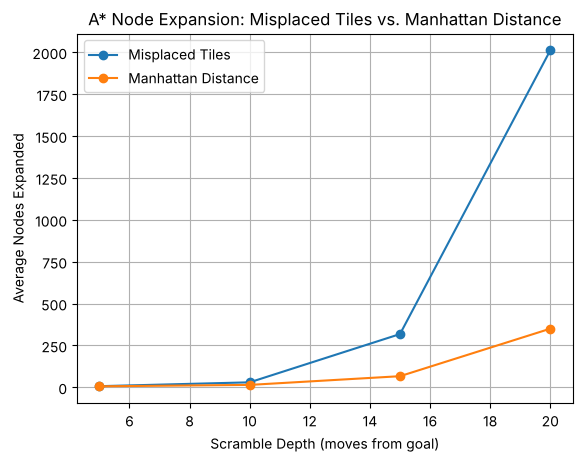

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(results)
summary = df.groupby("scramble_depth")[["misplaced_nodes", "manhattan_nodes"]].mean()
summary["ratio (Misplaced / Manhattan)"] = (summary["misplaced_nodes"] / summary["manhattan_nodes"]).round(2)
print(summary)

summary[["misplaced_nodes", "manhattan_nodes"]].plot(marker="o")
plt.xlabel("Scramble Depth (moves from goal)")
plt.ylabel("Average Nodes Expanded")
plt.title("A* Node Expansion: Misplaced Tiles vs. Manhattan Distance")
plt.legend(["Misplaced Tiles", "Manhattan Distance"])
plt.grid(True)
plt.show()

### Optional: how deep can each heuristic go?
We increase the scramble depth (3 trials per level) and record nodes expanded and wall-clock time.

In [14]:
import time

deep_rows = []
for depth in [24, 28, 32]:
    for trial in range(3):
        start = generate_scramble(depth, seed=trial * 1000 + depth)
        row = {"depth": depth, "trial": trial}
        for name, h in [("misplaced", misplaced_tiles), ("manhattan", manhattan_distance)]:
            t0 = time.time()
            r = a_star_search(start, h)
            row[f"{name}_nodes"] = r["nodes_expanded"]
            row[f"{name}_sec"] = round(time.time() - t0, 2)
            row["cost"] = r["cost"]
        deep_rows.append(row)

deep_df = pd.DataFrame(deep_rows)
print(deep_df.groupby("depth")[["misplaced_nodes", "manhattan_nodes", "misplaced_sec", "manhattan_sec"]].mean().round(1))

       misplaced_nodes  manhattan_nodes  misplaced_sec  manhattan_sec
depth                                                                
24              4809.3            879.3            0.0            0.0
28              3434.3            480.0            0.0            0.0
32             13216.0            790.3            0.1            0.0


In [15]:
# The hardest 8-puzzle positions need 31 moves (the maximum found by the full BFS above)
hardest = (8, 6, 7, 2, 5, 4, 3, 0, 1)
assert true_cost[hardest] == 31

for name, h in [("Misplaced Tiles", misplaced_tiles), ("Manhattan Distance", manhattan_distance)]:
    t0 = time.time()
    r = a_star_search(hardest, h)
    print(f"{name:20s} cost = {r['cost']} | nodes expanded = {r['nodes_expanded']:,} | time = {time.time() - t0:.2f} s")

Misplaced Tiles      cost = 31 | nodes expanded = 143,840 | time = 0.99 s
Manhattan Distance   cost = 31 | nodes expanded = 20,291 | time = 0.18 s


## 5. Analysis

**1. Table** (average nodes expanded over 5 trials per depth; output of the comparison cell above)

| Scramble depth | Misplaced Tiles | Manhattan Distance | Ratio |
|---:|---:|---:|---:|
| 5 | 7.0 | 6.2 | 1.13× |
| 10 | 30.0 | 14.6 | 2.05× |
| 15 | 318.0 | 66.6 | 4.77× |
| 20 | 2011.8 | 350.2 | 5.74× |

**2. Chart:** the line plot attached to the comparison cell shows Misplaced Tiles curving sharply upward while Manhattan Distance rises slowly. Both heuristics returned the same solution cost in all 20 trials (checked by an `assert`).

**3. Answers**

- **At what depth does the gap become clearly visible, and why does it widen?** At depth 5 the two are almost equal (7.0 vs 6.2). The gap is already clear at depth 10 (30.0 vs 14.6, about 2×) and large by depth 15 (318.0 vs 66.6, about 4.8×). It grows rather than staying constant because A\* expands every node whose f(n) = g(n) + h(n) is below the optimal solution cost, and a weaker heuristic leaves more nodes below that threshold. Misplaced Tiles counts every misplaced tile as exactly 1, however far away it is, so on deeper scrambles (where tiles are farther from home) it underestimates the true cost by more and more. That error compounds at each level of the search tree, so the number of extra nodes grows exponentially with depth and the ratio keeps increasing.

- **Why is a higher admissible heuristic not a violation of admissibility, and why does it expand fewer nodes?** Admissibility only requires h(n) ≤ h\*(n), where h\*(n) is the true remaining cost. It sets an upper bound, not a fixed value. Every misplaced tile contributes at least 1 to the Manhattan distance, so Manhattan ≥ Misplaced for every state, and Manhattan is still ≤ h\* (checked over all 181,440 solvable states in the admissibility cell: both heuristics are admissible and consistent). So 0 ≤ h_misplaced ≤ h_manhattan ≤ h\*, and Manhattan *dominates*. A larger h gives a larger f = g + h for the same node, so fewer nodes fall below the optimal cost and A\* expands fewer of them, while the answer remains optimal because h never overestimates.

- **(Optional) Does Manhattan hit the same wall at the same depth?** In the 8-puzzle neither hits a wall. The 3-trial runs at depths 24, 28 and 32 expanded on average only about 3,400 to 13,200 nodes for Misplaced Tiles and about 480 to 880 for Manhattan Distance (random-walk scrambles are rarely truly hard), and each run finished in well under a second. On the hardest 8-puzzle position (31 moves, the maximum), Misplaced Tiles expanded 143,840 nodes (about 0.9 s) and Manhattan Distance expanded 20,291 (about 0.2 s), roughly 7× fewer. So Manhattan does not hit the same wall at the same depth: the weaker heuristic's cost grows much faster, and on a larger puzzle (such as the 15-puzzle) it would become impractical long before Manhattan did.

## Submission Checklist
- ✅ `get_neighbors`, `misplaced_tiles`, `manhattan_distance` pass their checkpoints
- ✅ `a_star_search` passes the Cell 11 checkpoint
- ✅ Comparison over 4 scramble depths × 5 trials, with equal-cost assertion
- ✅ Table and chart generated
- ✅ Section 5 analysis answered